# Problem 1

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import statistics as st

# Part 1, single individual

In [ ]:
def sim_X(n,x0=0):
    """
    Simulates a realization of X for n days
    """
    # Transition probabilities
    b = 0.01 # P(S -> I)
    c = 0.10 # P(I -> R)
    a = 0.005 # P(R -> S)

    # Transition matrix for S = 0, I = 1, and R = 2
    P = np.array([[1-b, b, 0],
                [0, 1-c, c],
                [a, 0, 1-a]])

    # Cumulative transition probability array 
    P_cum = np.cumsum(P,axis=1)
    
    X = [x0]

    for _ in range(n):
        u = np.random.uniform(0,1) # random value between 0 and 1
        
        # Check the cumulative transition probabilites for the current state
        if u <= P_cum[X[-1]][0]:
            X.append(0)
        elif u <= P_cum[X[-1]][1]:
            X.append(1)
        else:
            X.append(2)

    return np.array(X)

In [4]:
def limiting_distribution(X):
    """
    Computes the sample limiting distribution of the last 10 years
    """
    X = X[3650:] # last 10 years

    # Estimating the limiting distribution of state i by the proportion of time spent in i
    pi_S = np.mean(X == 0)
    pi_I = np.mean(X == 1)
    pi_R = np.mean(X == 2)

    return (pi_S,pi_I,pi_R)


In [ ]:
def CI(x):
    """
    Computes 95% CI under normal assumption
    """
    mean = np.mean(x)
    se = st.stdev(x)/np.sqrt(len(x)) # standard error
    z = 1.645 # 95th quantile of the standard normal distribution
    return (mean-z*se,mean+z*se)

In [6]:
# Computing estimates for limiting distribution
realizations = [sim_X(7300) for _ in range(30)]
limiting_distributions = []
for realization in realizations:
    limiting_distributions.append(limiting_distribution(realization))

# Finding 95% confidence intervals
CI_s = CI([pi_s for pi_s, pi_i, pi_r in limiting_distributions])
CI_i = CI([pi_i for pi_s, pi_i, pi_r in limiting_distributions])
CI_r = CI([pi_r for pi_s, pi_i, pi_r in limiting_distributions])

print(f'95% CI for pi_s = [{CI_s[0]:.3f},{CI_s[1]:.3f}]')
print(f'95% CI for pi_s = [{CI_i[0]:.3f},{CI_i[1]:.3f}]')
print(f'95% CI for pi_s = [{CI_r[0]:.3f},{CI_r[1]:.3f}]')

print(f'95% CI for mean number of days spent per year in state S = [{365*CI_s[0]:.3f},{365*CI_s[1]:.3f}]')
print(f'95% CI for mean number of days spent per year in state I = [{365*CI_i[0]:.3f},{365*CI_i[1]:.3f}]')
print(f'95% CI for mean number of days spent per year in state R = [{365*CI_r[0]:.3f},{365*CI_r[1]:.3f}]')

95% CI for pi_s = [0.286,0.347]
95% CI for pi_s = [0.028,0.033]
95% CI for pi_s = [0.622,0.683]
95% CI for mean number of days spent per year in state S = [104.555,126.588]
95% CI for mean number of days spent per year in state I = [10.343,12.211]
95% CI for mean number of days spent per year in state R = [226.962,249.341]


# Part 2, varying infection rate

In [ ]:
def sim_Y(n,y0: tuple,N=1000):
    """
    Simulates a realization of Y for n days
    """
    # Fixed transition probabilities
    c = 0.10 # P(I -> R)
    a = 0.005 # P(R -> S)

    Y = [y0]

    for _ in range(n):

        # current number of individuals in each state
        S = Y[-1][0]
        I = Y[-1][1]
        R = Y[-1][2]

        # the probability that a Susceptible individual becomes Infected at this time:
        b = 0.5*I/N

        # Simulating transitions    
        dS = np.random.binomial(S,b) # number of individuals transitioning from S to I
        dI = np.random.binomial(I,c) # number of individuals transitioning from I to R
        dR = np.random.binomial(R,a) # number of individuals transitioning from R to S

        # updating S, I, and R
        S = S - dS + dR
        I = I - dI + dS
        R = R - dR + dI

        Y.append((S,I,R))
    
    return Y

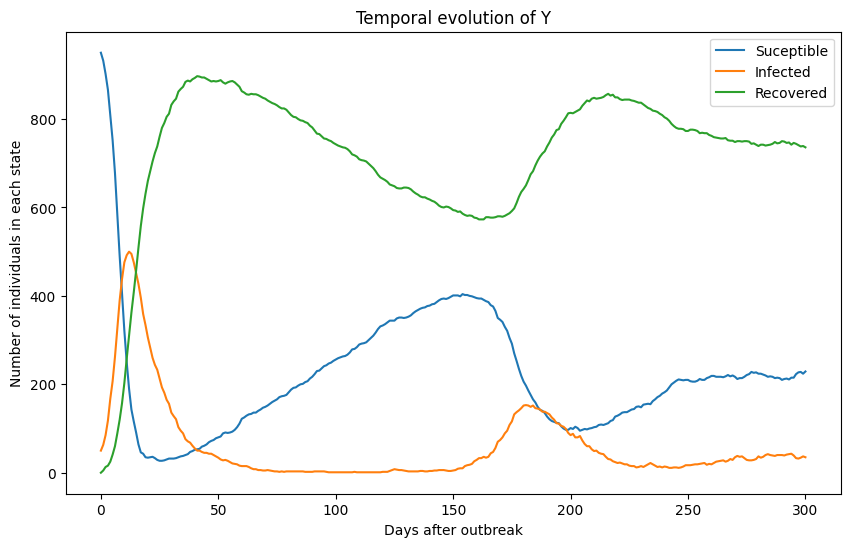

In [8]:
# Plotting temporal evolution
Y = sim_Y(300,(950,50,0))
fig = plt.figure(figsize=(10,6))
plt.plot([s for s,i,r in Y],label='Suceptible')
plt.plot([i for s,i,r in Y],label='Infected')
plt.plot([r for s,i,r in Y],label='Recovered')
plt.title('Temporal evolution of Y')
plt.xlabel('Days after outbreak')
plt.ylabel('Number of individuals in each state')
plt.legend()
plt.show()

In [ ]:
# Finding the maximum value of I_n of each realization and the time at which it occurs
def max_I(y0, N=1000):
    realizations = [sim_Y(300,y0,N) for _ in range(1000)]
    Imax = [] # Maximum value of I attained in each realization
    Imax_time = [] # Time at which maximum value of I is attained in each realization
    for realization in realizations:
        max = 0
        maxtime = 0
        for n in range(len(realization)):
            if realization[n][1] > max:
                max = realization[n][1]
                maxtime = n
        Imax.append(max)
        Imax_time.append(maxtime)
    return Imax,Imax_time

In [10]:
# Calculating CI
Imax,Imax_time = max_I((950,50,0))
CI_Imax = CI(Imax)
CI_Imax_time = CI(Imax_time)

print(f'95% CI for max I: [{CI_Imax[0]:.3f},{CI_Imax[1]:.3f}]')
print(f'95% CI for arg max I: [{CI_Imax_time[0]:.3f},{CI_Imax_time[1]:.3f}]')

95% CI for max I: [521.401,523.587]
95% CI for arg max I: [11.796,11.882]


# Part 3, vaccination


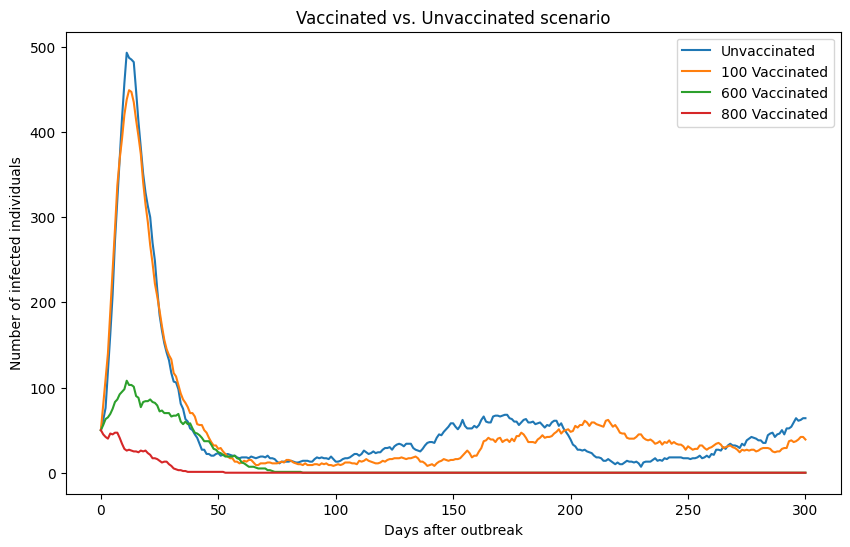

In [14]:
# No vaccination
Y = sim_Y(300,(950,50,0))

# With vaccination; 100 vaccinated individuals
Y_100 = sim_Y(300,(850,50,0),1000)

# With vaccination; 600 vaccinated individuals
Y_600 = sim_Y(300,(350,50,0),1000)

# With vaccination; 800 vaccinated individuals
Y_800 = sim_Y(300,(150,50,0),1000)

# Number of infected individuals
I = [i for s,i,r in Y]
I_100 = [i for s,i,r in Y_100]
I_600 = [i for s,i,r in Y_600]
I_800 = [i for s,i,r in Y_800]

# Plotting I over time
fig = plt.figure(figsize=(10,6))
plt.plot(I,label='Unvaccinated')
plt.plot(I_100,label='100 Vaccinated')
plt.plot(I_600,label='600 Vaccinated')
plt.plot(I_800,label='800 Vaccinated')
plt.title('Vaccinated vs. Unvaccinated scenario')
plt.xlabel('Days after outbreak')
plt.ylabel('Number of infected individuals')
plt.legend()
plt.show()


In [12]:
# Computing relevant quantities for vaccinated scenarios
Imax100,Imax_time100 = max_I((850,50,0),1000)
Imax600,Imax_time600 = max_I((350,50,0),1000)
Imax800,Imax_time800 = max_I((150,50,0),1000)

# Computing CI
CI_Imax100 = CI(Imax100)
CI_Imax_time100 = CI(Imax_time100)
CI_Imax600 = CI(Imax600)
CI_Imax_time600 = CI(Imax_time600)
CI_Imax800 = CI(Imax800)
CI_Imax_time800 = CI(Imax_time800)

print(f'95% CI for max I (100 vaccinated): [{CI_Imax100[0]:.3f},{CI_Imax100[1]:.3f}]')
print(f'95% CI for arg max I (100 vaccinated): [{CI_Imax_time100[0]:.3f},{CI_Imax_time100[1]:.3f}]')
print(f'95% CI for max I (600 vaccinated): [{CI_Imax600[0]:.3f},{CI_Imax600[1]:.3f}]')
print(f'95% CI for arg max I (600 vaccinated): [{CI_Imax_time600[0]:.3f},{CI_Imax_time600[1]:.3f}]')
print(f'95% CI for max I (800 vaccinated): [{CI_Imax800[0]:.3f},{CI_Imax800[1]:.3f}]')
print(f'95% CI for arg max I (800 vaccinated): [{CI_Imax_time800[0]:.3f},{CI_Imax_time800[1]:.3f}]')

95% CI for max I (100 vaccinated): [437.197,439.359]
95% CI for arg max I (100 vaccinated): [12.618,12.724]
95% CI for max I (600 vaccinated): [97.046,98.356]
95% CI for arg max I (600 vaccinated): [15.368,15.796]
95% CI for max I (800 vaccinated): [51.197,51.435]
95% CI for arg max I (800 vaccinated): [0.923,1.111]
